# 03. Exploratory analysis and charts

**Reads:** `data/comments_sentiment.csv`
**Writes:** PNG charts in `charts/`

Questions answered:
1. How does sentiment differ between dramas and between channels?
2. How does viewer mood change from the start to the end of a drama?
3. Which words stand out in positive and negative comments?
4. Do comment length and likes relate to sentiment?

Each drama has a 500-comment sample, so differences smaller than about 4 points should be treated as equal.

## Setup

In [1]:
import os, re, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

warnings.filterwarnings("ignore")
os.makedirs("charts", exist_ok=True)

df = pd.read_csv("data/comments_sentiment.csv")
df["published"] = pd.to_datetime(df["published"], errors="coerce")

CHANNEL = {"Sinf-e-Aahan": "ARY", "Mere Humsafar": "ARY",
           "Ishq Murshid": "Hum TV", "Parizaad": "Hum TV", "Humsafar": "Hum TV",
           "Ehd-e-Wafa": "Hum TV", "Suno Chanda": "Hum TV",
           "Jaan Nisar": "Geo", "Tere Bin": "Geo"}
df["channel"] = df["drama"].map(CHANNEL)
COLORS = {"positive": "#2e8b57", "neutral": "#b0b0b0", "negative": "#c0392b"}
print(len(df), "comments,", df["drama"].nunique(), "dramas")

4500 comments, 9 dramas


## 1. Sentiment by drama

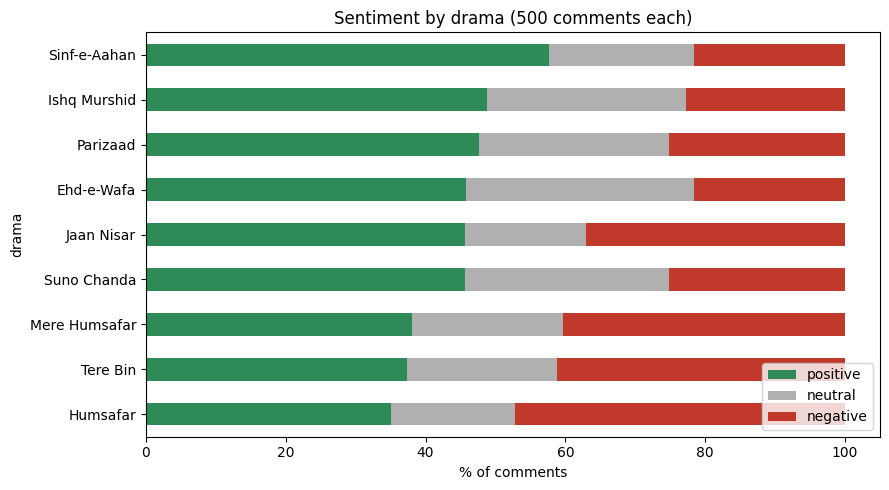

sentiment,positive,neutral,negative
drama,,,
Sinf-e-Aahan,57.6,20.8,21.6
Ishq Murshid,48.8,28.4,22.8
Parizaad,47.6,27.2,25.2
Ehd-e-Wafa,45.8,32.6,21.6
Suno Chanda,45.6,29.2,25.2
Jaan Nisar,45.6,17.4,37.0
Mere Humsafar,38.0,21.6,40.4
Tere Bin,37.4,21.4,41.2
Humsafar,35.0,17.8,47.2


In [2]:
pct = (df.groupby("drama")["sentiment"].value_counts(normalize=True)
         .unstack()[["positive", "neutral", "negative"]] * 100).sort_values("positive")

ax = pct.plot(kind="barh", stacked=True, figsize=(9, 5), color=[COLORS[c] for c in pct.columns])
ax.set_xlabel("% of comments")
ax.set_title("Sentiment by drama (500 comments each)")
ax.legend(loc="lower right")
plt.tight_layout()
plt.savefig("charts/1_drama_sentiment.png", dpi=150)
plt.show()

pct.round(1).sort_values("positive", ascending=False)

## 2. Sentiment by channel
ARY has only 2 dramas, Hum TV 5 and Geo 2, so compare channels with care.

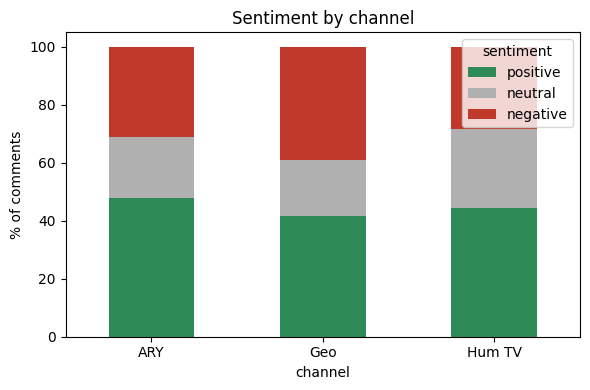

channel
ARY       2
Geo       2
Hum TV    5
Name: dramas, dtype: int64

In [3]:
ch = (df.groupby("channel")["sentiment"].value_counts(normalize=True)
        .unstack()[["positive", "neutral", "negative"]] * 100)

ax = ch.plot(kind="bar", stacked=True, figsize=(6, 4), color=[COLORS[c] for c in ch.columns], rot=0)
ax.set_ylabel("% of comments")
ax.set_title("Sentiment by channel")
plt.tight_layout()
plt.savefig("charts/2_channel_sentiment.png", dpi=150)
plt.show()

df.groupby("channel")["drama"].nunique().rename("dramas")

## 3. Mood through each drama
Each episode has only about 20 comments, so episodes are grouped into five stages from start to end.

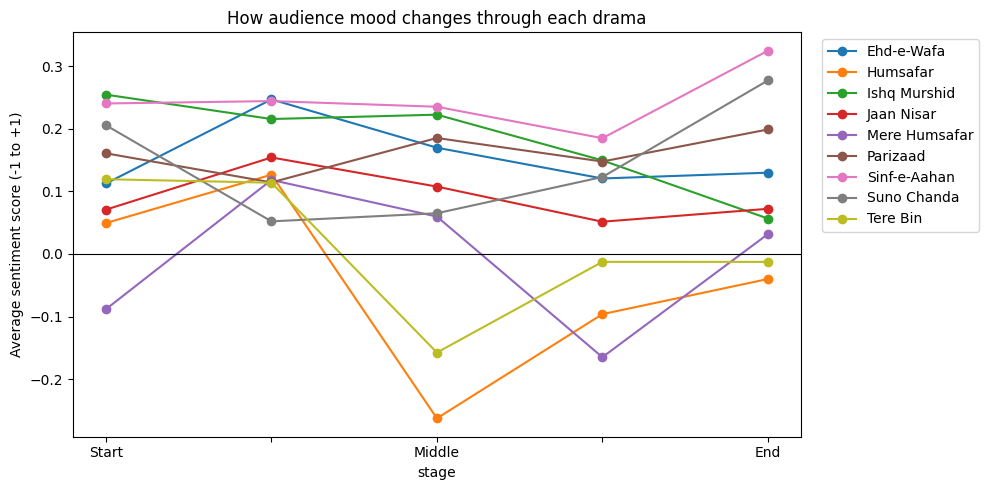

In [4]:
def stage(g):
    rel = (g["episode"] - g["episode"].min()) / max(1, g["episode"].max() - g["episode"].min())
    return np.minimum((rel * 5).astype(int), 4) + 1

df["stage"] = df.groupby("drama", group_keys=False).apply(stage)
trend = df.groupby(["drama", "stage"])["sent_score"].mean().unstack(0)

ax = trend.plot(figsize=(10, 5), marker="o")
ax.axhline(0, color="black", lw=0.8)
ax.set_xticks([1, 2, 3, 4, 5])
ax.set_xticklabels(["Start", "", "Middle", "", "End"])
ax.set_ylabel("Average sentiment score (-1 to +1)")
ax.set_title("How audience mood changes through each drama")
ax.legend(bbox_to_anchor=(1.02, 1), loc="upper left")
plt.tight_layout()
plt.savefig("charts/3_episode_trend.png", dpi=150)
plt.show()

## 4. Words in positive and negative comments
Common English and Roman Urdu filler words are removed. Add more to `roman_stop` if others show up.

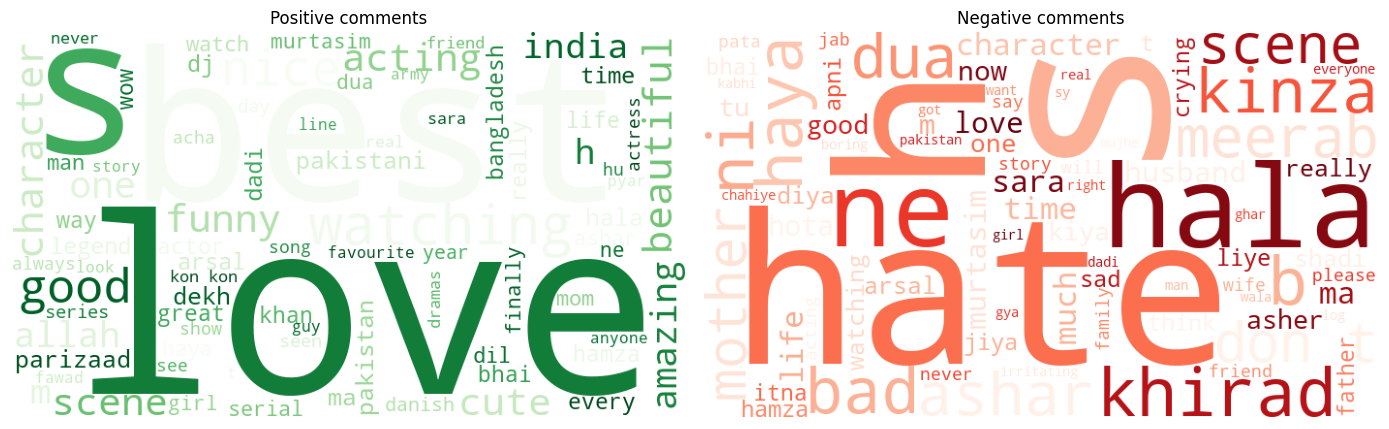

In [5]:
from wordcloud import WordCloud, STOPWORDS

roman_stop = set("""hai hain ho hoga hogi tha thi the ka ki ke ko se me mein pe par or aur ye yeh wo woh
 is us bhi to toh na nahi nhi kya kia ek hi hy ha hay bht bohat bahut jo ab ya
 kar kr kara karo kerna rha rhi rahi raha rahe lag lagta lagti drama episode part
 yar yaar sab koi kuch sath tum main mai hum mera meri apna uss iss""".split())
stop = STOPWORDS | roman_stop

def words(sent):
    t = " ".join(df.loc[df["sentiment"] == sent, "text_clean"].str.lower())
    return re.sub(r"[^a-z\s]", " ", t)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
for a, s, cmap in zip(axes, ["positive", "negative"], ["Greens", "Reds"]):
    wc = WordCloud(width=700, height=400, background_color="white",
                   stopwords=stop, colormap=cmap, max_words=80).generate(words(s))
    a.imshow(wc)
    a.axis("off")
    a.set_title(f"{s.title()} comments")
plt.tight_layout()
plt.savefig("charts/4_wordclouds.png", dpi=150)
plt.show()

## 5. Comment length and likes

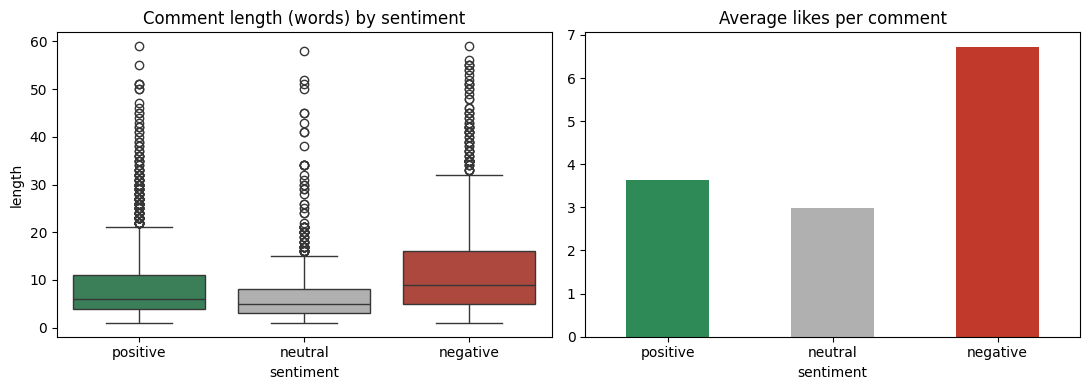

comments with 0 likes: 64 %


In [6]:
df["length"] = df["text_clean"].str.split().str.len()
fig, axes = plt.subplots(1, 2, figsize=(11, 4))

sns.boxplot(data=df[df["length"] < 60], x="sentiment", y="length",
            order=["positive", "neutral", "negative"], palette=COLORS, ax=axes[0])
axes[0].set_title("Comment length (words) by sentiment")

likes = df.groupby("sentiment")["likes"].mean().reindex(["positive", "neutral", "negative"])
likes.plot(kind="bar", color=[COLORS[c] for c in likes.index], rot=0, ax=axes[1])
axes[1].set_title("Average likes per comment")

plt.tight_layout()
plt.savefig("charts/5_length_likes.png", dpi=150)
plt.show()
print("comments with 0 likes:", round((df["likes"] == 0).mean() * 100), "%")

## Limitations
- The model was not trained specifically on Roman Urdu. Sarcasm and Bangla comments are often mislabelled. Its accuracy was not checked by hand-labelling.
- Each drama has 500 comments, so percentages carry about a plus or minus 4 point margin.
- "Negative" often reflects anger at a character, not dislike of the drama.
- Comments are the newest 500 per episode, not a sample across the whole life of each video.
- Many comments give no opinion ("which episode is this", "watching from 2026") and are labelled neutral.
- ARY is represented by 2 dramas only.